<a href="https://colab.research.google.com/github/christianpm-hub/Practica-2.3-teachable_machine_con_python/blob/main/Copia_de_pr%C3%A1ctica_2_3_teachable_machine.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Teachable Machine**

En esta práctica se debe exportar el modelo que se genera en Teachable Machine.

A la hora de exportar el modelo, se puede exportar para Tensorflow.

También viene un fragmento de código para usar el modelo:

```
from keras.models import load_model  # TensorFlow is required for Keras to work
from PIL import Image, ImageOps  # Install pillow instead of PIL
import numpy as np

# Disable scientific notation for clarity
np.set_printoptions(suppress=True)

# Load the model
model = load_model("keras_Model.h5", compile=False)

# Load the labels
class_names = open("labels.txt", "r").readlines()

# Create the array of the right shape to feed into the keras model
# The 'length' or number of images you can put into the array is
# determined by the first position in the shape tuple, in this case 1
data = np.ndarray(shape=(1, 224, 224, 3), dtype=np.float32)

# Replace this with the path to your image
image = Image.open("<IMAGE_PATH>").convert("RGB")

# resizing the image to be at least 224x224 and then cropping from the center
size = (224, 224)
image = ImageOps.fit(image, size, Image.Resampling.LANCZOS)

# turn the image into a numpy array
image_array = np.asarray(image)

# Normalize the image
normalized_image_array = (image_array.astype(np.float32) / 127.5) - 1

# Load the image into the array
data[0] = normalized_image_array

# Predicts the model
prediction = model.predict(data)
index = np.argmax(prediction)
class_name = class_names[index]
confidence_score = prediction[0][index]

# Print prediction and confidence score
print("Class:", class_name[2:], end="")
print("Confidence Score:", confidence_score)

```

**Tarea**: subir 3 imágenes propias (una clara, una ambigua, una que no pertenezca a ninguna categoría) y anotar qué predice y con qué confianza.

**¡Ojo! Hay que cargar una  versión anterior de Keras**

In [19]:
# forzar TensorFlow a usar el comportamiento clásico de Keras 2
import os
os.environ['TF_USE_LEGACY_KERAS'] = '1'

import tensorflow as tf
import tf_keras as keras

print("Versión de TensorFlow:", tf.__version__)
print("Versión de TF-Keras (Legacy):", keras.__version__)

try:
    # Cargamos el modelo utilizando el módulo de compatibilidad oficial tf_keras
    model = keras.models.load_model('/keras_model.h5', compile=False)
    print("\n¡MODELO CARGADO CON ÉXITO!")
    model.summary()
except Exception as e:
    print(f"\nError al cargar: {e}")

Versión de TensorFlow: 2.21.0
Versión de TF-Keras (Legacy): 2.21.0

¡MODELO CARGADO CON ÉXITO!
Model: "sequential_4"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 sequential_1 (Sequential)   (None, 1280)              410208    
                                                                 
 sequential_3 (Sequential)   (None, 2)                 128300    
                                                                 
Total params: 538508 (2.05 MB)
Trainable params: 524428 (2.00 MB)
Non-trainable params: 14080 (55.00 KB)
_________________________________________________________________


¡MODELO CARGADO CON ÉXITO!


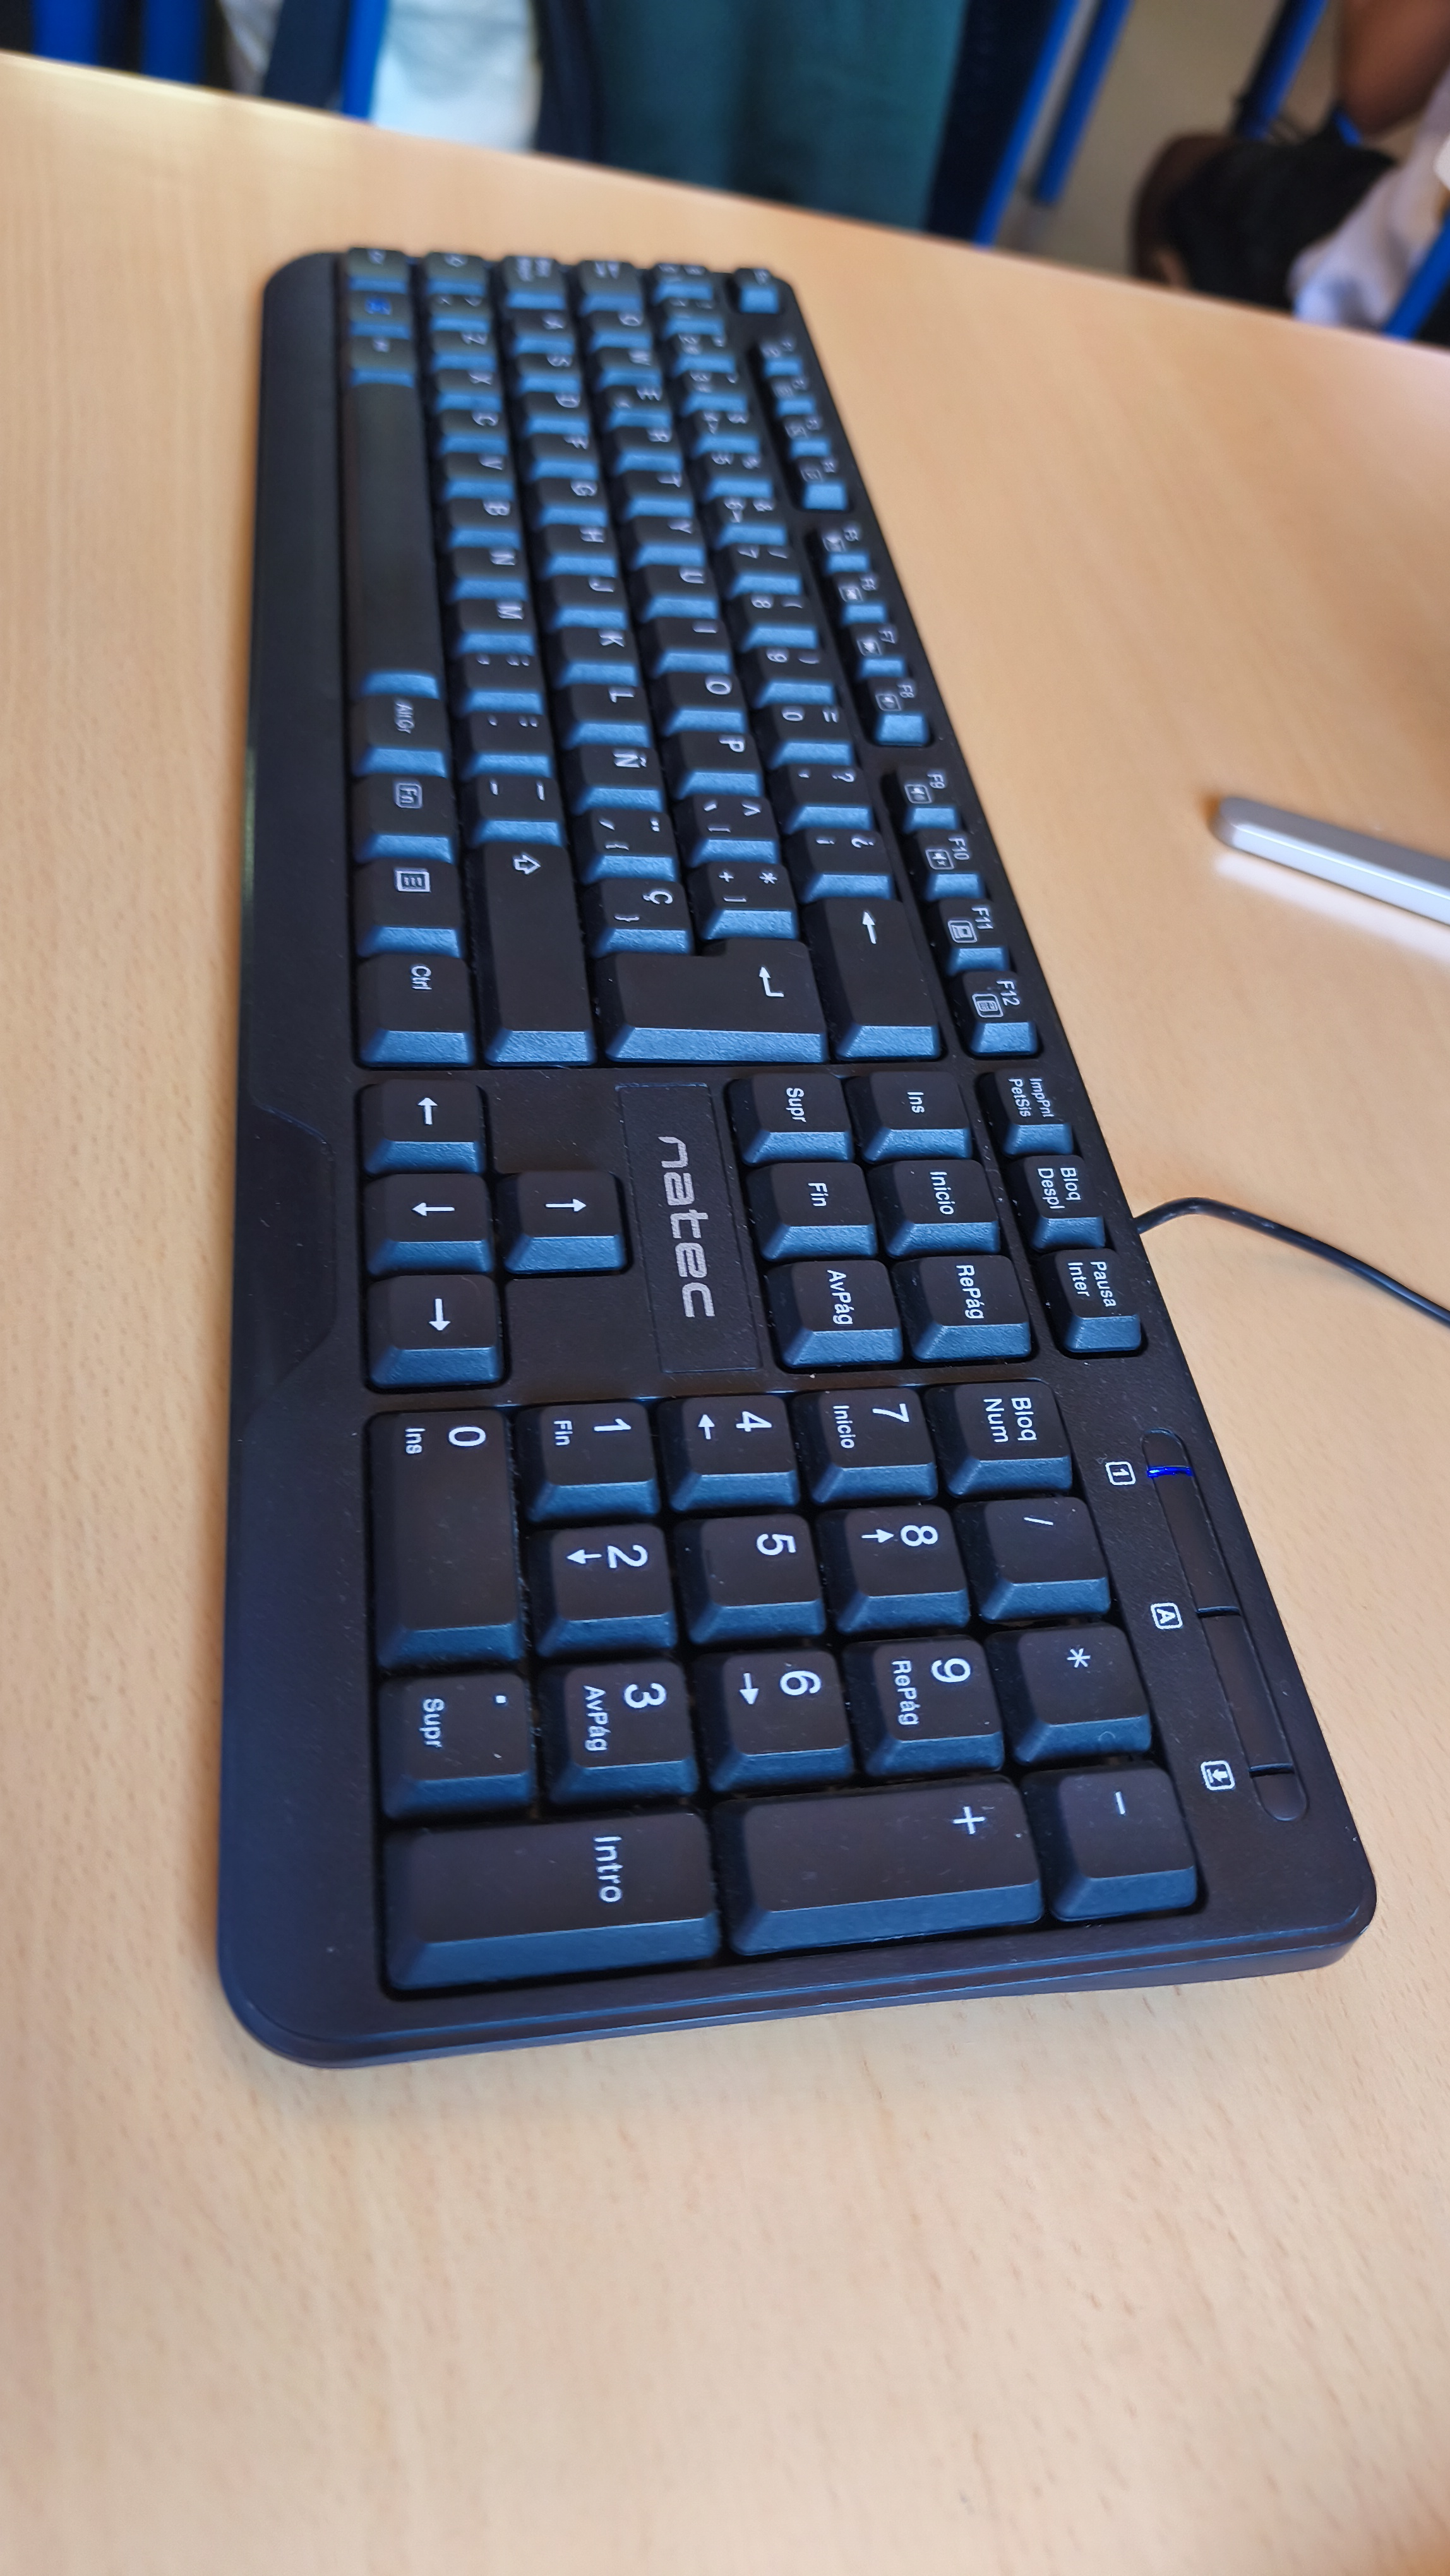

1/1 [==============================] - 1s 847ms/step
Class: Teclado
Confidence Score: 0.99999523


In [16]:
import os
os.environ['TF_USE_LEGACY_KERAS'] = '1'

import tensorflow as tf
import tf_keras as keras
from IPython.display import display, Image as IPImage



from keras.models import load_model  # TensorFlow is required for Keras to work
from PIL import Image, ImageOps  # Install pillow instead of PIL
import numpy as np

# Disable scientific notation for clarity
np.set_printoptions(suppress=True)

# Cargar el modelo con compatibilidad legacy
model = keras.models.load_model("/keras_model.h5", compile=False)
print("¡MODELO CARGADO CON ÉXITO!")

# Muestra la imagen correctamente (cambia el nombre por el archivo de tu foto)
display(IPImage(filename="/media/IMG_20260916_141311.jpg", width=300, height=300))

# Load the labels
class_names = open("/labels.txt", "r").readlines()

# Create the array of the right shape to feed into the keras model
# The 'length' or number of images you can put into the array is
# determined by the first position in the shape tuple, in this case 1
data = np.ndarray(shape=(1, 224, 224, 3), dtype=np.float32)

# Replace this with the path to your image
image = Image.open("/media/IMG_20260916_141311.jpg").convert("RGB")

# resizing the image to be at least 224x224 and then cropping from the center
size = (224, 224)
image = ImageOps.fit(image, size, Image.Resampling.LANCZOS)

# turn the image into a numpy array
image_array = np.asarray(image)

# Normalize the image
normalized_image_array = (image_array.astype(np.float32) / 127.5) - 1

# Load the image into the array
data[0] = normalized_image_array

# Predicts the model
prediction = model.predict(data)
index = np.argmax(prediction)
class_name = class_names[index]
confidence_score = prediction[0][index]

# Print prediction and confidence score
print("Class:", class_name[2:], end="")
print("Confidence Score:", confidence_score)


In [18]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


¡MODELO CARGADO CON ÉXITO!


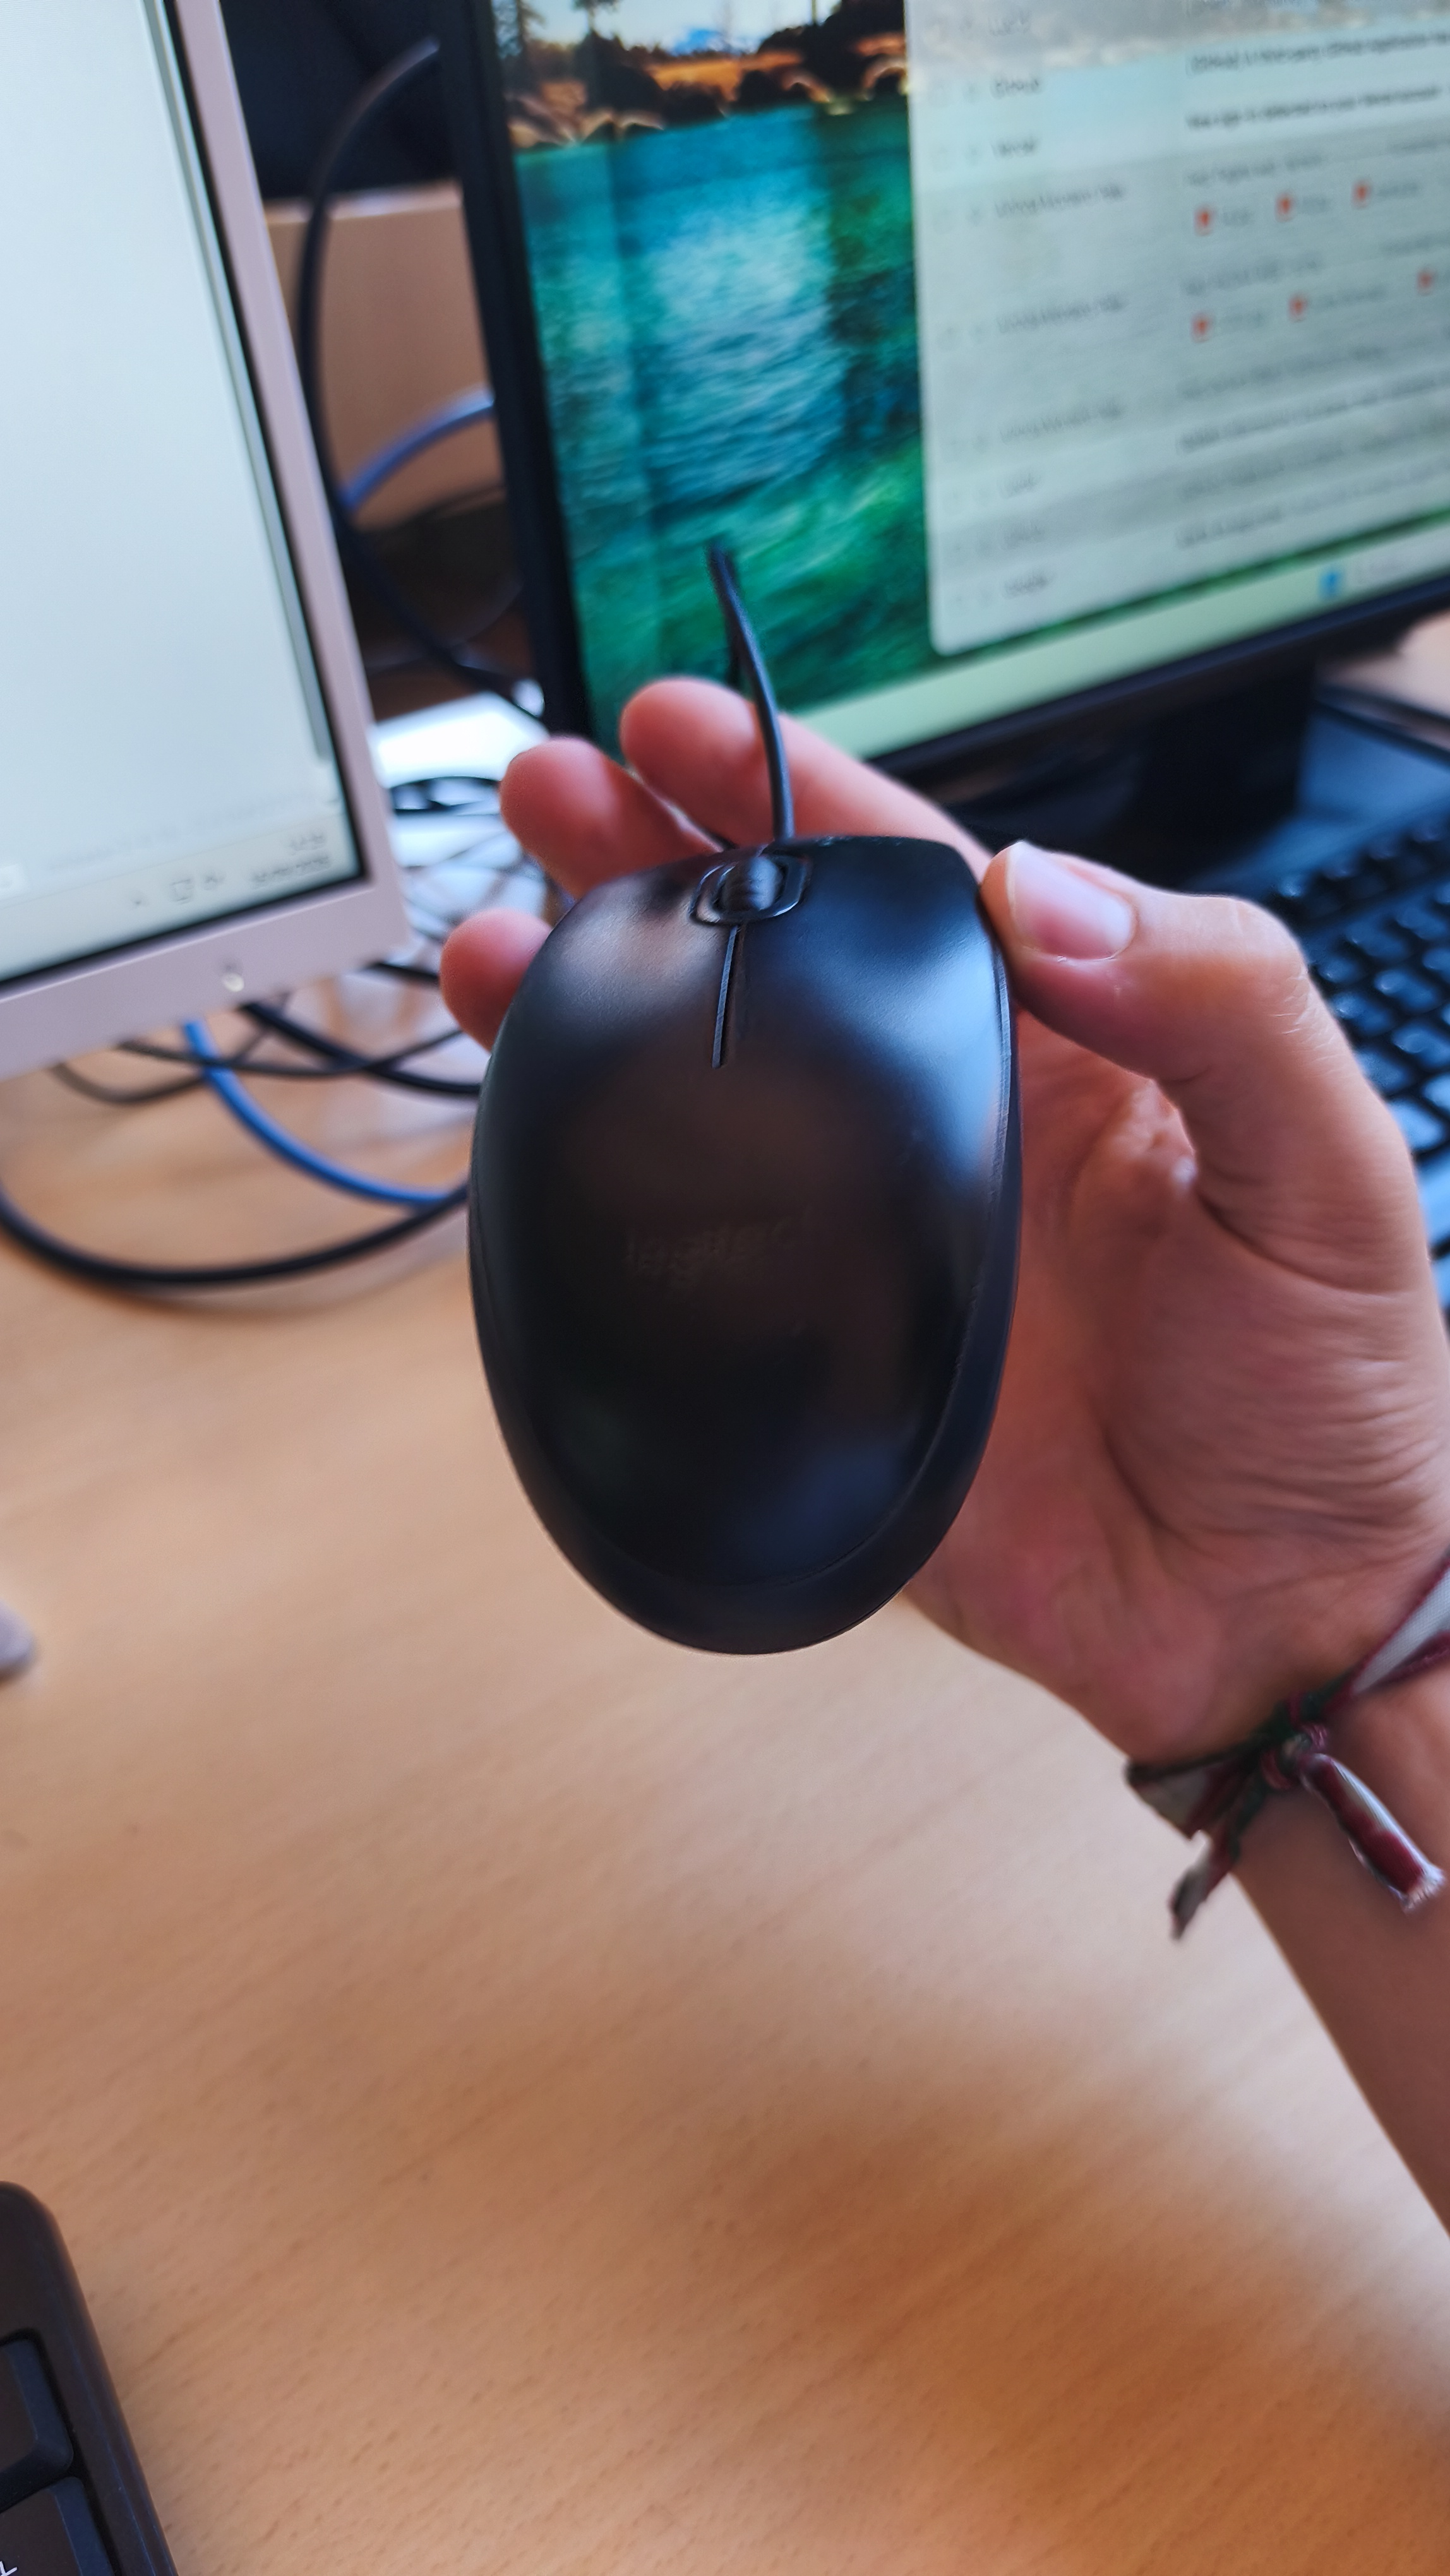

1/1 [==============================] - 1s 875ms/step
Class: Ratón
Confidence Score: 0.99999595


In [21]:
# implementa la clasificación con la imagen que pertenece claramente a una categoría
import os
os.environ['TF_USE_LEGACY_KERAS'] = '1'

import tensorflow as tf
import tf_keras as keras
from IPython.display import display, Image as IPImage



from keras.models import load_model  # TensorFlow is required for Keras to work
from PIL import Image, ImageOps  # Install pillow instead of PIL
import numpy as np

# Disable scientific notation for clarity
np.set_printoptions(suppress=True)

# Cargar el modelo con compatibilidad legacy
model = keras.models.load_model("/keras_model.h5", compile=False)
print("¡MODELO CARGADO CON ÉXITO!")

# Muestra la imagen correctamente (cambia el nombre por el archivo de tu foto)
display(IPImage(filename="/IMG_20260916_141940.jpg", width=200, height=300))

# Load the labels
class_names = open("/labels.txt", "r").readlines()

# Create the array of the right shape to feed into the keras model
# The 'length' or number of images you can put into the array is
# determined by the first position in the shape tuple, in this case 1
data = np.ndarray(shape=(1, 224, 224, 3), dtype=np.float32)

# Replace this with the path to your image
image = Image.open("/IMG_20260916_141940.jpg").convert("RGB")

# resizing the image to be at least 224x224 and then cropping from the center
size = (224, 224)
image = ImageOps.fit(image, size, Image.Resampling.LANCZOS)

# turn the image into a numpy array
image_array = np.asarray(image)

# Normalize the image
normalized_image_array = (image_array.astype(np.float32) / 127.5) - 1

# Load the image into the array
data[0] = normalized_image_array

# Predicts the model
prediction = model.predict(data)
index = np.argmax(prediction)
class_name = class_names[index]
confidence_score = prediction[0][index]

# Print prediction and confidence score
print("Class:", class_name[2:], end="")
print("Confidence Score:", confidence_score)

¡MODELO CARGADO CON ÉXITO!


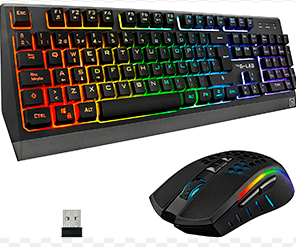

1/1 [==============================] - 1s 930ms/step
Class: Teclado
Confidence Score: 0.9997273


In [26]:
# implementa la clasificación con una imagen ambigua, que puede ser de cualquier categoría
import os
os.environ['TF_USE_LEGACY_KERAS'] = '1'

import tensorflow as tf
import tf_keras as keras
from IPython.display import display, Image as IPImage



from keras.models import load_model  # TensorFlow is required for Keras to work
from PIL import Image, ImageOps  # Install pillow instead of PIL
import numpy as np

# Disable scientific notation for clarity
np.set_printoptions(suppress=True)

# Cargar el modelo con compatibilidad legacy
model = keras.models.load_model("/keras_model.h5", compile=False)
print("¡MODELO CARGADO CON ÉXITO!")

# Muestra la imagen correctamente (cambia el nombre por el archivo de tu foto)
display(IPImage(filename="/Captura de pantalla 2026-11-10 000336.png", width=300, height=300))

# Load the labels
class_names = open("/labels.txt", "r").readlines()

# Create the array of the right shape to feed into the keras model
# The 'length' or number of images you can put into the array is
# determined by the first position in the shape tuple, in this case 1
data = np.ndarray(shape=(1, 224, 224, 3), dtype=np.float32)

# Replace this with the path to your image
image = Image.open("/Captura de pantalla 2026-11-10 000336.png").convert("RGB")

# resizing the image to be at least 224x224 and then cropping from the center
size = (224, 224)
image = ImageOps.fit(image, size, Image.Resampling.LANCZOS)

# turn the image into a numpy array
image_array = np.asarray(image)

# Normalize the image
normalized_image_array = (image_array.astype(np.float32) / 127.5) - 1

# Load the image into the array
data[0] = normalized_image_array

# Predicts the model
prediction = model.predict(data)
index = np.argmax(prediction)
class_name = class_names[index]
confidence_score = prediction[0][index]

# Print prediction and confidence score
print("Class:", class_name[2:], end="")
print("Confidence Score:", confidence_score)

¡MODELO CARGADO CON ÉXITO!


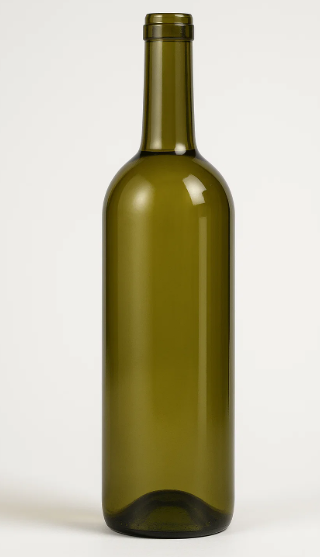

1/1 [==============================] - 1s 971ms/step
Class: Teclado
Confidence Score: 0.8114341


In [25]:
# implementa la clasificación con una imagen sin ninguna categoría del modelo
# implementa la clasificación con una imagen ambigua, que puede ser de cualquier categoría
import os
os.environ['TF_USE_LEGACY_KERAS'] = '1'

import tensorflow as tf
import tf_keras as keras
from IPython.display import display, Image as IPImage



from keras.models import load_model  # TensorFlow is required for Keras to work
from PIL import Image, ImageOps  # Install pillow instead of PIL
import numpy as np

# Disable scientific notation for clarity
np.set_printoptions(suppress=True)

# Cargar el modelo con compatibilidad legacy
model = keras.models.load_model("/keras_model.h5", compile=False)
print("¡MODELO CARGADO CON ÉXITO!")

# Muestra la imagen correctamente (cambia el nombre por el archivo de tu foto)
display(IPImage(filename="/Captura de pantalla 2026-11-10 000542.png", width=300, height=300))

# Load the labels
class_names = open("/labels.txt", "r").readlines()

# Create the array of the right shape to feed into the keras model
# The 'length' or number of images you can put into the array is
# determined by the first position in the shape tuple, in this case 1
data = np.ndarray(shape=(1, 224, 224, 3), dtype=np.float32)

# Replace this with the path to your image
image = Image.open("/Captura de pantalla 2026-11-10 000542.png").convert("RGB")

# resizing the image to be at least 224x224 and then cropping from the center
size = (224, 224)
image = ImageOps.fit(image, size, Image.Resampling.LANCZOS)

# turn the image into a numpy array
image_array = np.asarray(image)

# Normalize the image
normalized_image_array = (image_array.astype(np.float32) / 127.5) - 1

# Load the image into the array
data[0] = normalized_image_array

# Predicts the model
prediction = model.predict(data)
index = np.argmax(prediction)
class_name = class_names[index]
confidence_score = prediction[0][index]

# Print prediction and confidence score
print("Class:", class_name[2:], end="")
print("Confidence Score:", confidence_score)

**¿Cómo se usa el modelo exportado? ¿Cómo se comporta?**

---



Tienes que copiar el tensorflow y pegarlo para que funcione el teachable machine. Después te descargas el modelo, y metes en archivos el archivo keras, el labels, y las fotos con las que quieres comprobar el modelo.

En mi caso he añadido unas lineas para poder enseñar la imagen con la que se está comprobando

from IPython.display import display, Image as IPImage
display(IPImage(filename="/Captura de pantalla 2026-11-10 000542.png", width=300, height=300))